# Buổi 1 (bổ sung) — Đo hiệu năng các nguyên tắc tối ưu RDD
## PySpark cơ bản · Notebook thực nghiệm đi kèm slide *Phần 5*

Notebook này tạo ra **toàn bộ số liệu thật** được dùng trong slide Buổi 1 (các phần 4B, 4C, 5 — file `Slide_Buoi1_v2/Slide_Buoi1_RDD_v2.pdf`).
Mỗi thí nghiệm được trình bày theo một khuôn cố định:

| Bước | Nội dung |
|---|---|
| **Giả thuyết** | Ta kỳ vọng điều gì, dựa trên cơ chế nào của Spark |
| **Thiết kế** | Hai (hoặc nhiều) cách viết cho **cùng một kết quả**, chỉ khác đúng một yếu tố |
| **Đo** | Chỉ số khách quan: số lần gọi hàm, số byte/bản ghi shuffle, số task, thời gian |
| **Kết luận** | Nguyên tắc rút ra và phạm vi áp dụng |

### Ba loại chỉ số và độ tin cậy

| Chỉ số | Cách đo | Độ tin cậy |
|---|---|---|
| Số lần gọi hàm | `Accumulator` | **Tất định** — chạy lại ra đúng con số đó |
| Byte / bản ghi shuffle, số task | REST API của Spark UI | **Tất định** (sai khác rất nhỏ do nén) |
| Thời gian | `time.perf_counter`, lấy **min** của nhiều lần chạy sau 1 lần chạy nóng | **Dao động** theo máy và tải — chỉ nên so sánh **tỉ lệ** |

> **Lưu ý:** thời gian đo trên một laptop ở chế độ `local[*]`. Trên cluster thật, chi phí shuffle
> (đi qua mạng) còn **lớn hơn nhiều**, nên khoảng cách giữa cách viết tốt và cách viết kém thường **rộng hơn**.

## 0. Chuẩn bị

### 0.1 Khởi tạo Spark

Hai biến môi trường `PYSPARK_PYTHON` / `PYSPARK_DRIVER_PYTHON` đảm bảo Driver và Executor dùng **cùng
một trình thông dịch Python** — nếu khác phiên bản, Spark sẽ báo lỗi
`Python in worker has different version ... than that in driver`.

`spark.ui.showConsoleProgress=false` tắt thanh tiến trình để output gọn.

In [1]:
import os, sys, time, json, platform, subprocess
from operator import add
from urllib.request import urlopen

os.environ.setdefault("PYSPARK_PYTHON", sys.executable)
os.environ.setdefault("PYSPARK_DRIVER_PYTHON", sys.executable)

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("Buoi1-ToiUu")
         .master("local[*]")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
sc = spark.sparkContext
sc.setLogLevel("ERROR")

DATA   = "/home/lucas/Desktop/Github/BigData/homework/week6/BaiTap _Mapreduce/data"   # sua lai neu can
SCALE  = 200    # nhan ban access.log 200 lan -> 1.2 trieu dong
REPEAT = 3      # so lan do (lay min) sau 1 lan chay nong
RESULTS = {}    # noi luu moi so lieu -> ghi ra output/ketqua_toiuu.json

print("Spark", spark.version, "| Spark UI:", sc.uiWebUrl)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/09/29 23:15:56 WARN Utils: Your hostname, lucas-Dell-G15-5525, resolves to a loopback address: 127.0.1.1; using 192.168.2.28 instead (on interface wlp4s0)
26/09/29 23:15:56 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


/home/lucas/Desktop/Github/BigData/homework/bigdata-env/lib/python3.12/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/09/29 23:15:56 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.2.0 | Spark UI: http://192.168.2.28:4040


### 0.2 Ghi lại cấu hình máy đo

Một phép đo hiệu năng **không có ý nghĩa** nếu không kèm cấu hình máy. Ô dưới ghi lại CPU, số core,
RAM, phiên bản phần mềm — slide *5.2 Phương pháp đo* lấy thông tin từ đây.

In [2]:
def cpu_name():
    try:
        return subprocess.check_output(["sysctl", "-n", "machdep.cpu.brand_string"]).decode().strip()
    except Exception:
        return platform.processor() or "unknown"

def ram_gb():
    try:
        return round(os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 2**30, 1)
    except (ValueError, OSError, AttributeError):
        try:   # macOS khong ho tro SC_PHYS_PAGES
            return round(int(subprocess.check_output(["sysctl", "-n", "hw.memsize"])) / 2**30, 1)
        except Exception:
            return None

RESULTS["moi_truong"] = {
    "cpu": cpu_name(),
    "so_core_spark": sc.defaultParallelism,
    "ram_gb": ram_gb(),
    "he_dieu_hanh": platform.platform(),
    "python": platform.python_version(),
    "spark": spark.version,
    "master": sc.master,
}
RESULTS["moi_truong"]

sysctl: cannot stat /proc/sys/machdep/cpu/brand_string: No such file or directory


{'cpu': 'x86_64',
 'so_core_spark': 12,
 'ram_gb': 14.9,
 'he_dieu_hanh': 'Linux-7.0.0-34-generic-x86_64-with-glibc2.39',
 'python': '3.12.3',
 'spark': '4.2.0',
 'master': 'local[*]'}

### 0.3 Dữ liệu thí nghiệm

`access.log` chỉ có 6000 dòng — quá nhỏ để thấy khác biệt về thời gian. Ta **nhân bản mỗi dòng
200 lần** bằng `flatMap` để được **1,2 triệu dòng**. Mỗi bản sao được **biến đổi nhẹ** (octet cuối
của IP và latency ±20 ms) để dữ liệu không trùng lặp y hệt — nếu không, bộ nén của Spark sẽ nén
dữ liệu shuffle tốt một cách phi thực tế. Các trường `level`, `method`, `endpoint`, `status` giữ
nguyên, nên phân bố không đổi:

- `ERROR` ≈ 6,1% số dòng (toàn bộ là mã 5xx), `WARN` ≈ 6,4% (mã 4xx), còn lại `INFO` (mã 200).
- `/api/search` chiếm ≈ 55% số request — một ví dụ **lệch dữ liệu (skew)** tự nhiên.

RDD `base` được **`cache()`** ngay từ đầu. Mục đích: loại bỏ thời gian đọc file khỏi mọi phép đo,
để chỉ còn lại đúng phần ta muốn so sánh (tính toán, shuffle, truyền dữ liệu về Driver).

In [3]:
def nhan_ban(line):
    level, ip, method, endpoint, status, latency = line.split()
    a, b, c, d = ip.split(".")
    ms = int(latency[:-2])
    for k in range(SCALE):
        yield (f"{level} {a}.{b}.{c}.{(int(d) + 37 * k) % 256} {method} {endpoint} "
               f"{status} {max(1, ms + (k * 13) % 41 - 20)}ms")

raw  = sc.textFile(f"{DATA}/access.log", 8)                  # 6000 dong, 8 partition
base = raw.flatMap(nhan_ban).cache()                          # 1.2 trieu dong
N = base.count()

RESULTS["du_lieu"] = {"so_dong_goc": raw.count(), "he_so_nhan": SCALE,
                      "so_dong": N, "so_partition": base.getNumPartitions()}
RESULTS["du_lieu"]

{'so_dong_goc': 6000, 'he_so_nhan': 200, 'so_dong': 1200000, 'so_partition': 8}

### 0.4 Công cụ đo

- **`parse(line)`** — hàm tách một dòng log thành tuple 6 trường
  `(level, ip, method, endpoint, status, latency)`, trong đó `status` và `latency` đã là `int`.
- **`counted(fn, acc)`** — bọc một hàm để mỗi lần được gọi thì cộng 1 vào `Accumulator`.
  Dùng `acc.add(1)` thay cho `global acc; acc += 1` — gọn hơn và không cần khai báo `global`.
- **`bench(fn)`** — chạy nóng 1 lần, sau đó đo `REPEAT` lần, trả về thời gian **nhỏ nhất**
  (giá trị ít bị nhiễu bởi các tiến trình khác nhất).
- **`stage_metrics(group)`** — đọc REST API của Spark UI (`/api/v1/applications/<id>/stages`) để
  lấy số task và số byte/bản ghi shuffle của **mọi stage** thuộc một *job group*. Ta gắn nhãn job
  group bằng `sc.setJobGroup(...)` trước khi chạy Action.

In [4]:
def parse(line):
    c = line.split()
    return (c[0], c[1], c[2], c[3], int(c[4]), int(c[5][:-2]))

def counted(fn, acc):
    def wrapper(x):
        acc.add(1)
        return fn(x)
    return wrapper

def bench(fn, repeat=REPEAT, warmup=True):
    if warmup:
        fn()
    best, out = float("inf"), None
    for _ in range(repeat):
        t0 = time.perf_counter()
        out = fn()
        best = min(best, time.perf_counter() - t0)
    return round(best, 3), out

def stage_metrics(group):
    time.sleep(1.5)                       # listener cua Spark UI cap nhat bat dong bo
    api = f"{sc.uiWebUrl}/api/v1/applications/{sc.applicationId}"
    jobs = json.load(urlopen(api + "/jobs"))
    stage_ids = {s for j in jobs if j.get("jobGroup") == group for s in j["stageIds"]}
    m = {"so_stage": 0, "so_task": 0, "shuffle_write_bytes": 0,
         "shuffle_write_records": 0, "shuffle_read_bytes": 0}
    for sid in stage_ids:
        for att in json.load(urlopen(f"{api}/stages/{sid}")):
            if att["status"] != "COMPLETE":
                continue
            m["so_stage"] += 1
            m["so_task"] += att["numCompleteTasks"]
            m["shuffle_write_bytes"] += att["shuffleWriteBytes"]
            m["shuffle_write_records"] += att["shuffleWriteRecords"]
            m["shuffle_read_bytes"] += att["shuffleReadBytes"]
    return m

def run_in_group(group, fn):
    sc.setJobGroup(group, group)
    try:
        return fn()
    finally:
        sc.setLocalProperty("spark.jobGroup.id", None)

parse(base.first())

('ERROR', '10.0.3.185', 'POST', '/api/search', 502, 338)

---
## Thí nghiệm 1 — Lazy evaluation và `cache()` *(slide 4.20, 4.21)*

**Giả thuyết.** Transformation chỉ ghi vào DAG; mỗi Action chạy lại **toàn bộ** chuỗi từ đầu. Vậy
gọi `count()` hai lần trên một RDD **không cache** thì hàm `map` chạy **2 × 6000 = 12000** lần;
có `cache()` thì chỉ **6000** lần.

**Thiết kế.** Dùng file gốc 6000 dòng (`raw`), đếm số lần gọi `parse` bằng `Accumulator`.

In [5]:
acc_no = sc.accumulator(0)
rdd_no = raw.map(counted(parse, acc_no))
rdd_no.count(); rdd_no.count()

acc_c = sc.accumulator(0)
rdd_c = raw.map(counted(parse, acc_c)).cache()
rdd_c.count(); rdd_c.count()
rdd_c.unpersist()

RESULTS["tn1_lazy_cache"] = {"so_lan_goi_khong_cache": acc_no.value,
                             "so_lan_goi_co_cache": acc_c.value}
RESULTS["tn1_lazy_cache"]

{'so_lan_goi_khong_cache': 12000, 'so_lan_goi_co_cache': 6000}

**Kết luận.** Mỗi Action là một lần "thanh toán hoá đơn" cho toàn bộ chuỗi transformation phía trước.
`cache()` biến lần tính thứ hai thành lần **đọc lại từ bộ nhớ executor**.

---
## Thí nghiệm 2 — Nguyên tắc 1: lọc **trước** phép biến đổi đắt tiền *(slide 5.3)*

**Giả thuyết.** Với RDD, Spark **không** tự đổi thứ tự `map` và `filter` (hàm là hộp đen). Nếu lọc
trước, hàm `parse` chỉ phải chạy trên ~6% số dòng.

**Thiết kế.** Cùng kết quả: *đếm số dòng `ERROR`*.

| Cách | Chuỗi phép toán |
|---|---|
| A (chưa tối ưu) | `map(parse)` → `filter(level == "ERROR")` |
| B (tối ưu) | `filter(line.startswith("ERROR"))` → `map(parse)` |

> Lọc trên chuỗi thô chỉ **đúng** khi điều kiện tương đương với điều kiện sau khi parse. Ở đây
> `LEVEL` luôn là từ đầu tiên của dòng nên `startswith("ERROR")` ⇔ `r[0] == "ERROR"`.

In [6]:
a_A, a_B = sc.accumulator(0), sc.accumulator(0)
kq_A = base.map(counted(parse, a_A)).filter(lambda r: r[0] == "ERROR").count()
kq_B = base.filter(lambda l: l.startswith("ERROR")).map(counted(parse, a_B)).count()
assert kq_A == kq_B

t_A, _ = bench(lambda: base.map(parse).filter(lambda r: r[0] == "ERROR").count())
t_B, _ = bench(lambda: base.filter(lambda l: l.startswith("ERROR")).map(parse).count())

RESULTS["tn2_loc_truoc_map"] = {
    "ket_qua": kq_A,
    "A_so_lan_parse": a_A.value, "B_so_lan_parse": a_B.value,
    "A_giay": t_A, "B_giay": t_B,
    "giam_so_lan_goi": round(a_A.value / a_B.value, 1), "tang_toc": round(t_A / t_B, 1)}
RESULTS["tn2_loc_truoc_map"]

{'ket_qua': 73200,
 'A_so_lan_parse': 1200000,
 'B_so_lan_parse': 73200,
 'A_giay': 0.219,
 'B_giay': 0.102,
 'giam_so_lan_goi': 16.4,
 'tang_toc': 2.1}

**Kết luận.** Số lần gọi `parse` giảm đúng bằng tỉ lệ dòng bị loại. Mức tăng tốc về thời gian nhỏ
hơn mức giảm số lần gọi, vì cả hai cách vẫn phải **duyệt toàn bộ** 1,2 triệu dòng để lọc. Hàm càng
đắt (regex, parse JSON, gọi mô hình…) thì lợi ích càng lớn.

---
## Thí nghiệm 3 — Nguyên tắc 2: lọc **trước** shuffle *(slide 5.4)*

**Giả thuyết.** Shuffle là bước đắt nhất (ghi đĩa + mạng + serialize). Mỗi bản ghi bị loại **trước**
shuffle là một bản ghi không phải đi qua đó.

**Thiết kế.** Cùng kết quả: *số cặp (endpoint, IP) khác nhau có phát sinh lỗi*.

| Cách | Chuỗi phép toán |
|---|---|
| A | `map(parse)` → `map((level, endpoint, ip))` → **`distinct()`** → `filter(level == "ERROR")` |
| B | `map(parse)` → `filter(level == "ERROR")` → `map((endpoint, ip))` → **`distinct()`** |

In [7]:
def tn3_A():
    return (base.map(parse).map(lambda r: (r[0], r[3], r[1])).distinct()
                .filter(lambda t: t[0] == "ERROR").count())

def tn3_B():
    return (base.map(parse).filter(lambda r: r[0] == "ERROR")
                .map(lambda r: (r[3], r[1])).distinct().count())

kq_A = run_in_group("tn3_A", tn3_A); m_A = stage_metrics("tn3_A")
kq_B = run_in_group("tn3_B", tn3_B); m_B = stage_metrics("tn3_B")
assert kq_A == kq_B
t_A, _ = bench(tn3_A)
t_B, _ = bench(tn3_B)

RESULTS["tn3_loc_truoc_shuffle"] = {
    "ket_qua": kq_A, "A": m_A, "B": m_B, "A_giay": t_A, "B_giay": t_B,
    "giam_shuffle_bytes": round(m_A["shuffle_write_bytes"] / m_B["shuffle_write_bytes"], 1),
    "tang_toc": round(t_A / t_B, 1)}
RESULTS["tn3_loc_truoc_shuffle"]

{'ket_qua': 13400,
 'A': {'so_stage': 2,
  'so_task': 16,
  'shuffle_write_bytes': 1761756,
  'shuffle_write_records': 832,
  'shuffle_read_bytes': 1761756},
 'B': {'so_stage': 2,
  'so_task': 16,
  'shuffle_write_bytes': 366986,
  'shuffle_write_records': 587,
  'shuffle_read_bytes': 366986},
 'A_giay': 0.53,
 'B_giay': 0.294,
 'giam_shuffle_bytes': 4.8,
 'tang_toc': 1.8}

**Kết luận.** Lọc sau `distinct()` buộc Spark shuffle cả những bản ghi `INFO`/`WARN` rồi mới vứt
chúng đi. `distinct()` đã tự gộp trùng cục bộ trên từng partition trước khi shuffle (map-side combine),
nên con số byte ở đây nhỏ; với `join` hoặc `groupByKey` — không có bước gộp cục bộ — khoảng cách
sẽ còn lớn hơn nhiều.

---
## Thí nghiệm 4 — Nguyên tắc 3: bớt cột và gộp cục bộ trước shuffle *(slide 5.5)*

**Giả thuyết.** Có **hai** yếu tố độc lập làm giảm lượng shuffle:
1. **Chiếu cột (projection):** mỗi bản ghi nhẹ hơn nếu chỉ mang theo cột cần dùng.
2. **Gộp cục bộ (map-side combine):** `reduceByKey` cộng dồn trong từng partition **trước** khi gửi
   đi; `groupByKey` thì gửi **tất cả** giá trị.

**Thiết kế.** Cùng kết quả: *tổng latency theo endpoint*. Ba cách, mỗi bước chỉ đổi **một** yếu tố:

| Cách | Mang theo | Phép gom |
|---|---|---|
| A | cả dòng (6 trường) | `groupByKey` |
| B | chỉ `(endpoint, latency)` | `groupByKey` |
| C | chỉ `(endpoint, latency)` | `reduceByKey` |

In [8]:
def tn4_A():
    return sorted(base.map(parse).map(lambda r: (r[3], r)).groupByKey()
                      .mapValues(lambda rs: sum(x[5] for x in rs)).collect())

def tn4_B():
    return sorted(base.map(parse).map(lambda r: (r[3], r[5])).groupByKey()
                      .mapValues(sum).collect())

def tn4_C():
    return sorted(base.map(parse).map(lambda r: (r[3], r[5]))
                      .reduceByKey(add).collect())

out = {}
for name, fn in [("A", tn4_A), ("B", tn4_B), ("C", tn4_C)]:
    kq = run_in_group(f"tn4_{name}", fn)
    out[name] = {"ket_qua": kq, **stage_metrics(f"tn4_{name}")}
assert out["A"]["ket_qua"] == out["B"]["ket_qua"] == out["C"]["ket_qua"]
for name, fn in [("A", tn4_A), ("B", tn4_B), ("C", tn4_C)]:
    out[name]["giay"], _ = bench(fn)
    out[name].pop("ket_qua")

RESULTS["tn4_bot_cot_gop_cuc_bo"] = out
for k, v in out.items():
    print(k, v)

A {'so_stage': 2, 'so_task': 16, 'shuffle_write_bytes': 11880712, 'shuffle_write_records': 24, 'shuffle_read_bytes': 11880712, 'giay': 1.045}
B {'so_stage': 2, 'so_task': 16, 'shuffle_write_bytes': 407400, 'shuffle_write_records': 24, 'shuffle_read_bytes': 407400, 'giay': 0.37}
C {'so_stage': 2, 'so_task': 16, 'shuffle_write_bytes': 2484, 'shuffle_write_records': 24, 'shuffle_read_bytes': 2484, 'giay': 0.328}


> **Vì sao cột `shuffle_write_records` bằng nhau ở cả ba cách?** Trong PySpark, `groupByKey` được cài
> đặt bằng cách gom các giá trị của cùng một key thành **một list Python** trong từng partition rồi mới
> gửi đi, nên phía JVM chỉ đếm được "một bản ghi mỗi key mỗi partition". Kích thước thật nằm trong
> list đó — vì vậy **số byte** mới là chỉ số phản ánh đúng khối lượng shuffle.

**Kết luận.** So sánh A→B cho thấy tác dụng của **chiếu cột**; B→C cho thấy tác dụng của **gộp cục
bộ**. Với `reduceByKey`, mỗi partition chỉ gửi đi **một bản ghi cho mỗi key** (6 endpoint), bất kể
partition có bao nhiêu dòng. Đây là lý do quy tắc "**ưu tiên `reduceByKey` hơn `groupByKey`**".

---
## Thí nghiệm 5 — Nguyên tắc 4: không kéo dữ liệu thừa về Driver *(slide 5.6)*

**Giả thuyết.** `collect()` chuyển **toàn bộ** RDD về một máy duy nhất (Driver) rồi xử lý bằng Python
đơn luồng. Lọc trên Spark trước thì phần việc nặng được làm **song song** và chỉ phần kết quả nhỏ
đi về Driver.

**Thiết kế.** Cùng kết quả: *danh sách các request lỗi 5xx*.

| Cách | Chuỗi phép toán |
|---|---|
| A | `map(parse)` → **`collect()`** → lọc bằng list comprehension trên Driver |
| B | `map(parse)` → `filter(status >= 500)` → **`collect()`** |

In [9]:
def tn5_A():
    return [r for r in base.map(parse).collect() if r[4] >= 500]

def tn5_B():
    return base.map(parse).filter(lambda r: r[4] >= 500).collect()

t_A, kq_A = bench(tn5_A)
t_B, kq_B = bench(tn5_B)
assert sorted(kq_A) == sorted(kq_B)

RESULTS["tn5_khong_collect_thua"] = {
    "A_so_dong_ve_driver": N, "B_so_dong_ve_driver": len(kq_B),
    "A_giay": t_A, "B_giay": t_B,
    "giam_du_lieu_ve_driver": round(N / len(kq_B), 1), "tang_toc": round(t_A / t_B, 1)}
del kq_A, kq_B
RESULTS["tn5_khong_collect_thua"]

{'A_so_dong_ve_driver': 1200000,
 'B_so_dong_ve_driver': 73200,
 'A_giay': 0.767,
 'B_giay': 0.243,
 'giam_du_lieu_ve_driver': 16.4,
 'tang_toc': 3.2}

**Kết luận.** Ngoài chậm hơn, cách A còn **nguy hiểm**: với dữ liệu thật (hàng chục GB) Driver sẽ
hết bộ nhớ (`OutOfMemoryError`). Quy tắc: *chỉ `collect()` khi chắc chắn kết quả đủ nhỏ*.

---
## Thí nghiệm 6 — Nguyên tắc 5: `cache()` khi RDD được dùng lại *(slide 5.7)*

**Giả thuyết.** Nếu một RDD được dùng cho nhiều Action mà không cache, toàn bộ chuỗi phía trước
chạy lại cho **mỗi** Action. Cache thì chỉ chạy một lần.

**Nhưng cache không miễn phí.** Trong PySpark, dữ liệu cache được lưu dưới dạng **byte đã serialize**
(pickle) trong bộ nhớ JVM. Mỗi lần đọc cache, Spark phải gửi byte sang Python worker và **giải
serialize** lại. Vậy cache chỉ có lợi khi *chi phí tính lại* **lớn hơn** *chi phí ghi + đọc cache*.

**Thiết kế.** Hai kịch bản:

| Kịch bản | Bước phía trước (phần có thể được cache) | Số Action |
|---|---|---|
| 6a — rẻ | `parse` trên dữ liệu **đã nằm trong bộ nhớ** | 3 |
| 6b — đắt | **đọc file** + `parse` + **ẩn danh IP bằng SHA-256** | 5 (vòng lặp theo ngưỡng latency) |

Mỗi lần đo tạo RDD **mới** (và `unpersist()` sau đó), để thời gian có cache bao gồm cả chi phí nạp cache.

In [10]:
def ba_action(rdd):
    return (rdd.filter(lambda r: r[0] == "ERROR").count(),
            rdd.filter(lambda r: r[4] >= 500).count(),
            rdd.map(lambda r: r[5]).sum())

def tn6a(use_cache, acc=None):
    fn = counted(parse, acc) if acc is not None else parse
    rdd = base.map(fn)
    if use_cache:
        rdd = rdd.cache()
    kq = ba_action(rdd)
    if use_cache:
        rdd.unpersist()
    return kq

a_no, a_c = sc.accumulator(0), sc.accumulator(0)
assert tn6a(False, a_no) == tn6a(True, a_c)
t_no, _ = bench(lambda: tn6a(False))
t_c, _ = bench(lambda: tn6a(True))

RESULTS["tn6a_cache_buoc_re"] = {
    "so_action": 3, "A_so_lan_parse": a_no.value, "B_so_lan_parse": a_c.value,
    "A_giay": t_no, "B_giay": t_c, "tang_toc": round(t_no / t_c, 1)}
RESULTS["tn6a_cache_buoc_re"]

{'so_action': 3,
 'A_so_lan_parse': 3600000,
 'B_so_lan_parse': 1200000,
 'A_giay': 0.567,
 'B_giay': 0.629,
 'tang_toc': 0.9}

Kịch bản 6b cần một **file thật** trên đĩa. Ô dưới ghi 1,2 triệu dòng ra thư mục
`output/access_x200/` (8 file `part-*`, khoảng 55 MB), sau đó đọc lại bằng `textFile`.

Hàm `parse_an_danh` mô phỏng bước làm sạch thường gặp khi xử lý log có dữ liệu cá nhân: kiểm tra định
dạng IP bằng biểu thức chính quy rồi thay IP bằng giá trị băm SHA-256.

In [11]:
import shutil, hashlib, re

SRC = "output/access_x200"
shutil.rmtree(SRC, ignore_errors=True)
base.saveAsTextFile(SRC)

IP_RE = re.compile(r"^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}$")

def parse_an_danh(line):
    r = parse(line)
    if not IP_RE.match(r[1]):
        return None
    ip_bam = hashlib.sha256(r[1].encode()).hexdigest()[:16]
    return (r[0], ip_bam, r[2], r[3], r[4], r[5])

NGUONG = [100, 300, 500, 700, 900]

def tn6b(use_cache, acc=None):
    fn = counted(parse_an_danh, acc) if acc is not None else parse_an_danh
    rdd = sc.textFile(SRC).map(fn)
    if use_cache:
        rdd = rdd.cache()
    kq = [rdd.filter(lambda r, t=t: r[5] > t).count() for t in NGUONG]   # vong lap 5 Action
    if use_cache:
        rdd.unpersist()
    return kq

a_no, a_c = sc.accumulator(0), sc.accumulator(0)
assert tn6b(False, a_no) == tn6b(True, a_c)
t_no, _ = bench(lambda: tn6b(False))
t_c, _ = bench(lambda: tn6b(True))

RESULTS["tn6b_cache_buoc_dat"] = {
    "so_action": len(NGUONG), "A_so_lan_parse": a_no.value, "B_so_lan_parse": a_c.value,
    "A_giay": t_no, "B_giay": t_c, "tang_toc": round(t_no / t_c, 1)}
RESULTS["tn6b_cache_buoc_dat"]

{'so_action': 5,
 'A_so_lan_parse': 6000000,
 'B_so_lan_parse': 1200000,
 'A_giay': 2.722,
 'B_giay': 1.213,
 'tang_toc': 2.2}

**Kết luận.** Số lần gọi hàm luôn giảm đúng bằng số Action, nhưng **thời gian** chỉ giảm rõ khi phần
được cache là phần **đắt** (đọc file, parse phức tạp, shuffle, gọi mô hình…). Quy tắc thực hành:

- Cache khi RDD được dùng **≥ 2 lần** **và** chuỗi phía trước **đắt hơn** việc đọc lại cache.
- Không cache những bước rẻ ngay trên dữ liệu đã nằm trong bộ nhớ — chỉ tốn RAM.
- Vòng lặp (thuật toán học máy, tìm tham số) là trường hợp cache có lợi nhất.

---
## Thí nghiệm 7 — Nguyên tắc 6: `mapPartitions` cho bước chuẩn bị đắt tiền *(slide 5.8)*

**Giả thuyết.** Nhiều bài toán cần một bước **chuẩn bị** trước khi xử lý từng dòng: nạp bảng tra cứu,
mở kết nối cơ sở dữ liệu, nạp mô hình ML… Nếu đặt bước đó trong `map`, nó chạy **mỗi dòng một lần**;
với `mapPartitions`, nó chạy **mỗi partition một lần**.

**Thiết kế.** Mô phỏng bước chuẩn bị bằng `load_lookup()` — dựng bảng tra cứu 4096 địa chỉ IP →
vùng mạng. Dùng tập con 24.000 dòng (cách A quá chậm nếu chạy trên 1,2 triệu dòng).

In [12]:
def load_lookup():
    # Mo phong buoc chuan bi dat tien: nap bang tra cuu IP -> vung mang
    return {f"10.0.{a}.{b}": f"zone-{a % 4}" for a in range(16) for b in range(256)}

t0 = time.perf_counter(); load_lookup(); t_setup_ms = (time.perf_counter() - t0) * 1000

small = raw.flatMap(lambda line: [line] * 4).cache()     # 24.000 dong, 8 partition
n_small = small.count()

def tn7_A(acc=None):
    def zone_of(line):
        if acc is not None: acc.add(1)
        lookup = load_lookup()                   # chuan bi: MOI DONG mot lan
        return lookup.get(line.split()[1], "unknown")
    return sorted(small.map(zone_of).countByValue().items())

def tn7_B(acc=None):
    def zone_of_partition(lines):
        if acc is not None: acc.add(1)
        lookup = load_lookup()                   # chuan bi: MOI PARTITION mot lan
        for line in lines:
            yield lookup.get(line.split()[1], "unknown")
    return sorted(small.mapPartitions(zone_of_partition).countByValue().items())

a_A, a_B = sc.accumulator(0), sc.accumulator(0)
assert tn7_A(a_A) == tn7_B(a_B)
t_A, _ = bench(tn7_A, repeat=2, warmup=False)
t_B, _ = bench(tn7_B, repeat=2, warmup=False)

RESULTS["tn7_mappartitions"] = {
    "so_dong": n_small, "chi_phi_chuan_bi_ms": round(t_setup_ms, 2),
    "A_so_lan_chuan_bi": a_A.value, "B_so_lan_chuan_bi": a_B.value,
    "A_giay": t_A, "B_giay": t_B, "tang_toc": round(t_A / t_B, 1)}
small.unpersist()
RESULTS["tn7_mappartitions"]

{'so_dong': 24000,
 'chi_phi_chuan_bi_ms': 1.45,
 'A_so_lan_chuan_bi': 24000,
 'B_so_lan_chuan_bi': 8,
 'A_giay': 4.819,
 'B_giay': 0.019,
 'tang_toc': 253.6}

**Kết luận.** Số lần chuẩn bị giảm từ *số dòng* xuống *số partition*. Đây là mẫu chuẩn khi ghi dữ
liệu ra cơ sở dữ liệu (mở một kết nối cho mỗi partition, không phải cho mỗi dòng) hoặc khi suy
luận bằng mô hình ML trên Spark.

---
## Thí nghiệm 8 — Nguyên tắc 7: `coalesce()` sau khi lọc mạnh *(slide 5.9)*

**Giả thuyết.** Sau một phép lọc giữ lại rất ít dữ liệu, số partition **không đổi** — ta có hàng
trăm partition gần như rỗng. Mỗi partition vẫn sinh ra một task, và mỗi task có chi phí lập lịch cố
định. `coalesce(n)` gộp các partition kề nhau **mà không shuffle**.

**Thiết kế.** Chia lại dữ liệu thành 400 partition (mô phỏng file lớn có nhiều block), lọc giữ
~2,8% dòng (`ERROR` + `GET`), rồi tính tổng latency theo endpoint.

| Cách | Sau khi lọc |
|---|---|
| A | giữ nguyên 400 partition |
| B | `coalesce(8)` |

In [13]:
many = base.repartition(400).cache()
many.count()

def loc_manh(l):
    return l.startswith("ERROR") and " GET " in l

def tn8_A():
    return sorted(many.filter(loc_manh).map(parse).map(lambda r: (r[3], r[5]))
                      .reduceByKey(add).collect())

def tn8_B():
    return sorted(many.filter(loc_manh).coalesce(8).map(parse).map(lambda r: (r[3], r[5]))
                      .reduceByKey(add).collect())

kq_A = run_in_group("tn8_A", tn8_A); m_A = stage_metrics("tn8_A")
kq_B = run_in_group("tn8_B", tn8_B); m_B = stage_metrics("tn8_B")
assert kq_A == kq_B
t_A, _ = bench(tn8_A)
t_B, _ = bench(tn8_B)

RESULTS["tn8_coalesce"] = {
    "so_dong_sau_loc": many.filter(loc_manh).count(),
    "A": m_A, "B": m_B, "A_giay": t_A, "B_giay": t_B, "tang_toc": round(t_A / t_B, 1)}
many.unpersist()
RESULTS["tn8_coalesce"]

{'so_dong_sau_loc': 33600,
 'A': {'so_stage': 2,
  'so_task': 800,
  'shuffle_write_bytes': 121229,
  'shuffle_write_records': 1437,
  'shuffle_read_bytes': 121229},
 'B': {'so_stage': 2,
  'so_task': 16,
  'shuffle_write_bytes': 2497,
  'shuffle_write_records': 24,
  'shuffle_read_bytes': 2497},
 'A_giay': 2.722,
 'B_giay': 0.988,
 'tang_toc': 2.8}

**Kết luận.** Chi phí mỗi task (lập lịch, khởi động Python worker, serialize) là **cố định**, nên
khi mỗi task chỉ còn rất ít dữ liệu thì chi phí này chiếm phần lớn thời gian. Lưu ý: `coalesce` không
shuffle nên cũng **giảm mức song song** của các bước ngay trước nó trong cùng stage — đừng
`coalesce` xuống thấp hơn số core.

---
## Thí nghiệm 9 — Tính đúng đắn: `reduce` với hàm không kết hợp *(slide 4.22 – 4.25)*

**Giả thuyết.** `reduce(f)` gộp hai tầng: trong từng partition, rồi giữa các partition. Nếu `f` không
có **tính kết hợp**, kết quả **phụ thuộc số partition** — và Spark **không báo lỗi**.

**Thiết kế.**
1. Phép chia trên `[1, 2, 0.5, 0.1, 5, 0.2]` với 1, 2, 3, 6 partition.
2. "Trung bình" bằng `reduce(lambda x, y: (x + y) / 2)` trên 6000 giá trị latency, so với trung bình đúng.
3. Cách đúng: mang theo cặp `(tổng, số lượng)` — phép cộng có tính kết hợp — và chỉ chia **một lần** ở cuối.

In [14]:
so = [1, 2, .5, .1, 5, .2]
chia = {p: round(sc.parallelize(so, p).reduce(lambda x, y: x / y), 6) for p in (1, 2, 3, 6)}

lat = raw.map(lambda l: int(l.split()[5][:-2]))
tb_dung = lat.sum() / lat.count()
tb_sai = {p: round(lat.repartition(p).reduce(lambda x, y: (x + y) / 2), 2) for p in (1, 4, 8)}

tong, dem = lat.map(lambda x: (x, 1)).reduce(lambda a, b: (a[0] + b[0], a[1] + b[1]))

tb_endpoint = sorted(raw.map(parse)
                        .map(lambda r: (r[3], (r[5], 1)))
                        .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                        .mapValues(lambda s: round(s[0] / s[1], 1))
                        .collect())

RESULTS["tn9_tinh_dung_dan"] = {
    "reduce_chia_theo_so_partition": chia,
    "trung_binh_dung": round(tb_dung, 2),
    "trung_binh_sai_theo_so_partition": tb_sai,
    "trung_binh_tong_dem": round(tong / dem, 2),
    "trung_binh_theo_endpoint": tb_endpoint}
RESULTS["tn9_tinh_dung_dan"]

{'reduce_chia_theo_so_partition': {1: 10.0, 2: 10.0, 3: 0.004, 6: 10.0},
 'trung_binh_dung': 451.88,
 'trung_binh_sai_theo_so_partition': {1: 568.12, 4: 414.03, 8: 410.4},
 'trung_binh_tong_dem': 451.88,
 'trung_binh_theo_endpoint': [('/api/admin', 445.1),
  ('/api/cart', 457.7),
  ('/api/checkout', 465.4),
  ('/api/login', 446.4),
  ('/api/product', 461.5),
  ('/api/search', 447.3)]}

**Kết luận.** Cùng dữ liệu, cùng hàm, chỉ khác số partition → kết quả khác nhau. **Tính đúng của
`reduce` / `reduceByKey` là trách nhiệm của người viết hàm.** Mẫu thiết kế tổng quát: *tích luỹ một
đại lượng có tính kết hợp (tổng, số lượng, min, max), chỉ quy đổi ở bước cuối*.

---
## Thí nghiệm 10 — Áp dụng tổng hợp cho bài toán xuyên suốt *(slide 5.11)*

**Bài toán.** *Với mỗi endpoint: có bao nhiêu request lỗi (`ERROR`) và latency trung bình của các
request lỗi đó là bao nhiêu?*

| | Cách viết "ngây thơ" | Cách viết tối ưu |
|---|---|---|
| Lọc | Sau khi gom nhóm (trong Python) | Ngay đầu tiên, trên chuỗi thô (NT1, NT2) |
| Dữ liệu mang qua shuffle | Cả dòng (NT3) | `(latency, 1)` (NT3) |
| Phép gom | `groupByKey` | `reduceByKey` với cặp `(tổng, số lượng)` (NT3, tính đúng đắn) |

In [15]:
def pipeline_ngay_tho():
    return sorted(base.map(parse)
                      .map(lambda r: (r[3], r))
                      .groupByKey()
                      .mapValues(lambda rs: [x[5] for x in rs if x[0] == "ERROR"])
                      .mapValues(lambda ls: (len(ls), round(sum(ls) / len(ls), 1)))
                      .collect())

def pipeline_toi_uu():
    return sorted(base.filter(lambda l: l.startswith("ERROR"))
                      .map(lambda l: l.split())
                      .map(lambda c: (c[3], (int(c[5][:-2]), 1)))
                      .reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
                      .mapValues(lambda s: (s[1], round(s[0] / s[1], 1)))
                      .collect())

kq_A = run_in_group("tn10_A", pipeline_ngay_tho); m_A = stage_metrics("tn10_A")
kq_B = run_in_group("tn10_B", pipeline_toi_uu);   m_B = stage_metrics("tn10_B")
assert kq_A == kq_B
t_A, _ = bench(pipeline_ngay_tho)
t_B, _ = bench(pipeline_toi_uu)

RESULTS["tn10_pipeline_tong_hop"] = {
    "ket_qua": kq_B, "A": m_A, "B": m_B, "A_giay": t_A, "B_giay": t_B,
    "tang_toc": round(t_A / t_B, 1)}
RESULTS["tn10_pipeline_tong_hop"]

{'ket_qua': [('/api/admin', (2400, 341.3)),
  ('/api/cart', (9800, 482.8)),
  ('/api/checkout', (3000, 506.2)),
  ('/api/login', (5800, 425.3)),
  ('/api/product', (13600, 417.7)),
  ('/api/search', (38600, 421.8))],
 'A': {'so_stage': 2,
  'so_task': 16,
  'shuffle_write_bytes': 11880712,
  'shuffle_write_records': 24,
  'shuffle_read_bytes': 11880712},
 'B': {'so_stage': 2,
  'so_task': 16,
  'shuffle_write_bytes': 2684,
  'shuffle_write_records': 24,
  'shuffle_read_bytes': 2684},
 'A_giay': 1.053,
 'B_giay': 0.158,
 'tang_toc': 6.7}

---
## Tổng hợp kết quả

Bảng dưới gom các con số chính của mọi thí nghiệm; toàn bộ số liệu chi tiết được ghi ra
`output/ketqua_toiuu.json` để dùng lại (slide, báo cáo).

In [16]:
import pandas as pd

R = RESULTS
t4 = R["tn4_bot_cot_gop_cuc_bo"]
rows = [
    ("NT1 Lọc trước map",        "số lần parse",  R["tn2_loc_truoc_map"]["A_so_lan_parse"],  R["tn2_loc_truoc_map"]["B_so_lan_parse"],  R["tn2_loc_truoc_map"]["A_giay"],  R["tn2_loc_truoc_map"]["B_giay"]),
    ("NT2 Lọc trước shuffle",    "byte shuffle",  R["tn3_loc_truoc_shuffle"]["A"]["shuffle_write_bytes"], R["tn3_loc_truoc_shuffle"]["B"]["shuffle_write_bytes"], R["tn3_loc_truoc_shuffle"]["A_giay"], R["tn3_loc_truoc_shuffle"]["B_giay"]),
    ("NT3 Bớt cột + reduceByKey","byte shuffle",  t4["A"]["shuffle_write_bytes"], t4["C"]["shuffle_write_bytes"], t4["A"]["giay"], t4["C"]["giay"]),
    ("NT4 Lọc rồi mới collect",  "dòng về Driver",R["tn5_khong_collect_thua"]["A_so_dong_ve_driver"], R["tn5_khong_collect_thua"]["B_so_dong_ve_driver"], R["tn5_khong_collect_thua"]["A_giay"], R["tn5_khong_collect_thua"]["B_giay"]),
    ("NT5a Cache (bước rẻ)",     "số lần parse",  R["tn6a_cache_buoc_re"]["A_so_lan_parse"], R["tn6a_cache_buoc_re"]["B_so_lan_parse"], R["tn6a_cache_buoc_re"]["A_giay"], R["tn6a_cache_buoc_re"]["B_giay"]),
    ("NT5b Cache (bước đắt)",    "số lần parse",  R["tn6b_cache_buoc_dat"]["A_so_lan_parse"], R["tn6b_cache_buoc_dat"]["B_so_lan_parse"], R["tn6b_cache_buoc_dat"]["A_giay"], R["tn6b_cache_buoc_dat"]["B_giay"]),
    ("NT6 mapPartitions",        "lần chuẩn bị",  R["tn7_mappartitions"]["A_so_lan_chuan_bi"], R["tn7_mappartitions"]["B_so_lan_chuan_bi"], R["tn7_mappartitions"]["A_giay"], R["tn7_mappartitions"]["B_giay"]),
    ("NT7 coalesce sau lọc",     "số task",       R["tn8_coalesce"]["A"]["so_task"], R["tn8_coalesce"]["B"]["so_task"], R["tn8_coalesce"]["A_giay"], R["tn8_coalesce"]["B_giay"]),
    ("Pipeline tổng hợp",        "byte shuffle",  R["tn10_pipeline_tong_hop"]["A"]["shuffle_write_bytes"], R["tn10_pipeline_tong_hop"]["B"]["shuffle_write_bytes"], R["tn10_pipeline_tong_hop"]["A_giay"], R["tn10_pipeline_tong_hop"]["B_giay"]),
]
tong_hop = pd.DataFrame(rows, columns=["Nguyên tắc", "Chỉ số", "Trước", "Sau", "Trước (s)", "Sau (s)"])
tong_hop["Giảm chỉ số (lần)"] = (tong_hop["Trước"] / tong_hop["Sau"]).round(1)
tong_hop["Tăng tốc (lần)"] = (tong_hop["Trước (s)"] / tong_hop["Sau (s)"]).round(1)

os.makedirs("output", exist_ok=True)
with open("output/ketqua_toiuu.json", "w", encoding="utf-8") as f:
    json.dump(RESULTS, f, ensure_ascii=False, indent=2)
tong_hop

,Nguyên tắc,Chỉ số,Trước,Sau,Trước (s),Sau (s),Giảm chỉ số (lần),Tăng tốc (lần)
0,NT1 Lọc trước map,số lần parse,1200000,73200,0.219,0.102,16.4,2.1
1,NT2 Lọc trước shuffle,byte shuffle,1761756,366986,0.530,0.294,4.8,1.8
2,NT3 Bớt cột + reduceByKey,byte shuffle,11880712,2484,1.045,0.328,4782.9,3.2
3,NT4 Lọc rồi mới collect,dòng về Driver,1200000,73200,0.767,0.243,16.4,3.2
4,NT5a Cache (bước rẻ),số lần parse,3600000,1200000,0.567,0.629,3.0,0.9
5,NT5b Cache (bước đắt),số lần parse,6000000,1200000,2.722,1.213,5.0,2.2
6,NT6 mapPartitions,lần chuẩn bị,24000,8,4.819,0.019,3000.0,253.6
7,NT7 coalesce sau lọc,số task,800,16,2.722,0.988,50.0,2.8
8,Pipeline tổng hợp,byte shuffle,11880712,2684,1.053,0.158,4426.5,6.7


### Biểu đồ: thời gian trước và sau khi áp dụng từng nguyên tắc

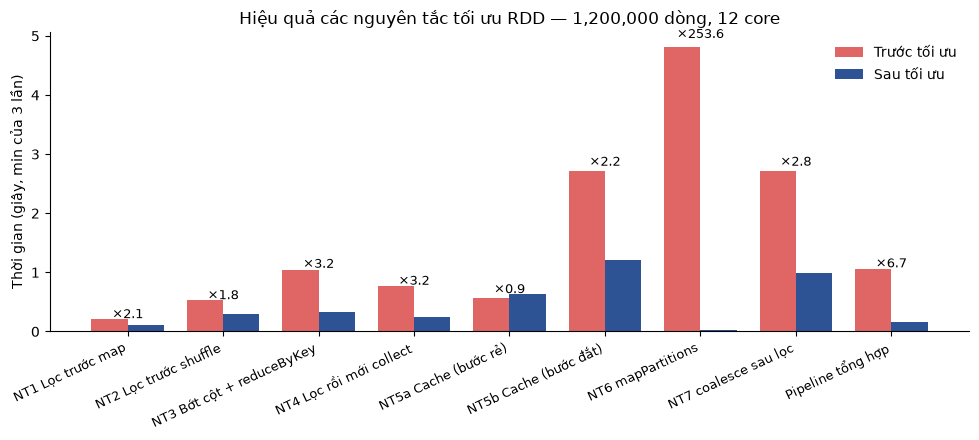

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4.5))
x = range(len(tong_hop))
w = 0.38
ax.bar([i - w/2 for i in x], tong_hop["Trước (s)"], w, label="Trước tối ưu", color="#E06666")
ax.bar([i + w/2 for i in x], tong_hop["Sau (s)"],   w, label="Sau tối ưu",   color="#2E5395")
for i, s in zip(x, tong_hop["Tăng tốc (lần)"]):
    ax.text(i, max(tong_hop.loc[i, "Trước (s)"], tong_hop.loc[i, "Sau (s)"]) * 1.03,
            f"×{s}", ha="center", fontsize=9)
ax.set_xticks(list(x))
ax.set_xticklabels(tong_hop["Nguyên tắc"], rotation=25, ha="right", fontsize=9)
ax.set_ylabel("Thời gian (giây, min của %d lần)" % REPEAT)
ax.set_title("Hiệu quả các nguyên tắc tối ưu RDD — %s dòng, %d core" % (f"{N:,}", sc.defaultParallelism))
ax.legend(frameon=False)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.savefig("output/bieudo_toiuu.png", dpi=150)
plt.show()

### Giải phóng tài nguyên

In [18]:
base.unpersist()
spark.stop()